In [40]:
import pandas as pd
# df = pd.read_csv('C:/users/arj26323/OneDrive - University of Georgia/Documents/Manuscripts/Network analysis/News articles/data/Test.csv', encoding='cp1252')
df = pd.read_csv('C:/users/arj26323/OneDrive - University of Georgia/Documents/Manuscripts/Network analysis/News articles/data/restoration_news.csv', encoding="utf-8")
df

,Title,FullText,Abstract,StoreId,ArticleType,Authors,companies,copyright,documentType,entryDate,...,notes,startPage,subjectClassifications,subjectTerms,subjects,FindACopy,Database,sentiment,analysis_text,masked_text
0,Port project's spiraling price,Costs keep rising to deepen the Savannah River...,Mitigate environmental damage Some Items On ...,963465691,newspapers,NaN,NaN,"(Copyright , The Atlanta Journal-Constitution...",News,"Apr 2, 2012",...,NaN,A.8,NaN,NaN,NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,Costs keep rising to deepen the Savannah River...,Costs keep rising to deepen the Savannah River...
1,BRYAN COUNTY NOW DECEMBER STUDENT OF THE MONTH...,NaN,"/b&gt; ""I enjoy decorating the Christmas tree ...",821863487,newspapers,BRYAN COUNTY NOW,NaN,(Copyright 2010 Savannah Morning News.),News,"Dec 30, 2010",...,NaN,A.6,NaN,"Morales, Crystal , Johnson, Joye , Fay, Veron...",NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,"/b&gt; ""I enjoy decorating the Christmas tree ...","/b&gt; ""I enjoy decorating the Christmas tree ..."
2,Program spurs oyster reef restoration,Nov. 06--When people shuck oyster shells at Co...,"In addition to using restaurant donations, the...",762549499,newspapers,"Fakour, Shanessa",NaN,To see more of The Brunswick News or to subsc...,News,"Nov 6, 2010",...,NaN,n/a,"72251 Restaurants and Other Eating Places , 5...","SUSTAINABILITY , INDUSTRY , SUSTAINABILITY , ...",NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,Nov. 06--When people shuck oyster shells at Co...,Nov. 06--When people shuck oyster shells at Co...
3,SPEND A SATURDAY ON MARINE SCIENCE,NaN,"""My classic all-time most-hated one is droppin...",757027518,newspapers,"Landers, Mary",NaN,(Copyright 2010 Savannah Morning News.),News,"Oct 7, 2010",...,NaN,E.10,NaN,"Savidge, Bill",NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,"""My classic all-time most-hated one is droppin...","""My classic all-time most-hated one is droppin..."
4,AQUARIUM FREE FOR ONE DAY,NaN,The University of Georgia Marine Extension Ser...,756925019,newspapers,NaN,NaN,(Copyright 2010 Savannah Morning News.),News,"Oct 6, 2010",...,NaN,A.9,NaN,NaN,NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,The University of Georgia Marine Extension Ser...,The University of Georgia Marine Extension Ser...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,"Southern Company, partners to award Five Star ...","ATLANTA, Aug. 5, 2014 /PRNewswire/ -- Southern...","Since 2006, Southern Company has contributed m...",1551178711,newspapers,NaN,"Southern Co , Birmingham-Southern College , A...","Copyright PR Newswire Association LLC Aug 5, ...",News,"Aug 5, 2014",...,NaN,n/a,NaN,"SUSTAINABILITY , SUSTAINABILITY , SUSTAINABIL...",NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,"ATLANTA, Aug. 5, 2014 /PRNewswire/ -- Southern...","ATLANTA, Aug. 5, 2014 /PRNewswire/ -- Southern..."
65,Former New Smyrna high school field being rest...,NEW SMYRNA BEACH\n\nAn empty field on the site...,Tractors began scraping away grass and soil ...,1544010721,newspapers,Dinah Voyles Pulver,Costa Del Mar,"Copyright Halifax Media Group Jul 09, 2014",News,"Jul 09, 2014",...,NaN,n/a,NaN,"Haydt, Paul",NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,NEW SMYRNA BEACH\n\nAn empty field on the site...,NEW SMYRNA BEACH\n\nAn empty field on the site...
66,CONGRESS COMES TO THE COAST,NaN,"""For 97 percent of us who study and write pa...",1521838754,newspapers,"Landers, Mary",American Meteorological Society,(Copyright 2014 Savannah Mornin

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set your plotting style
sns.set_theme(style="white")

# Count occurrences per year and sort chronologically
yearly_counts = df['year'].value_counts().sort_index()

# # Plotting
# plt.figure(figsize=(12, 6))
# ax = sns.barplot(x=yearly_counts.index, y=yearly_counts.values, color="black")

# plt.xlabel("Year", fontsize=12)
# plt.ylabel("Number of Articles", fontsize=12)

# # Rotate x-axis labels if you have many years, so they don't crowd
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()

sentiment
positive    59
neutral      8
negative     2
Name: count, dtype: int64


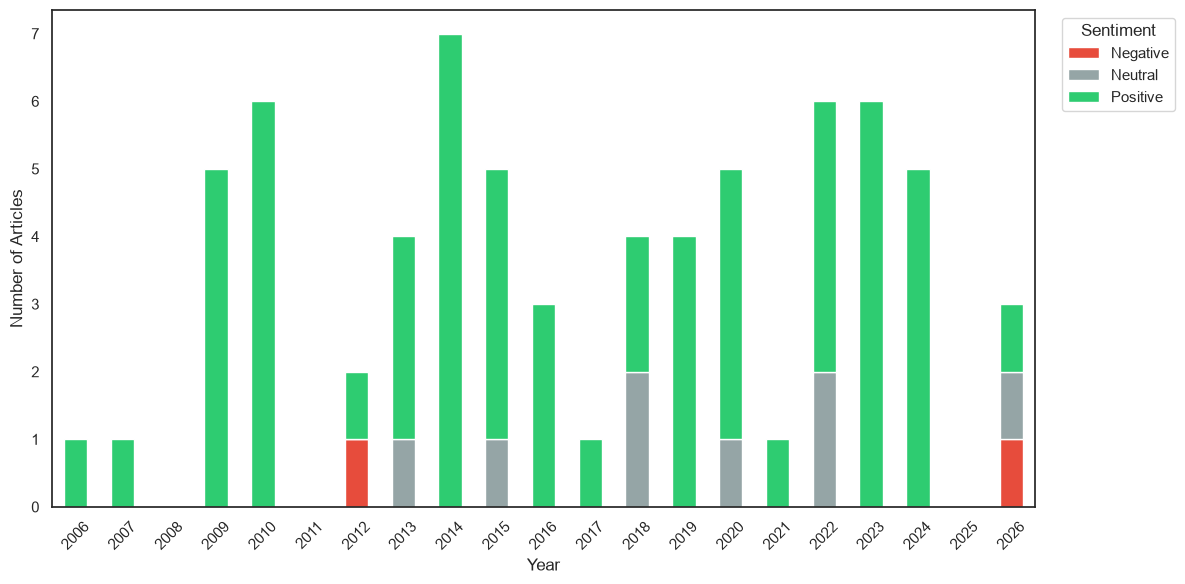

In [45]:
##Sentiment analysis (needs body text)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob


import re
import pandas as pd
from textblob import TextBlob

# 1. Define your domain-specific words to mask
# (These words appear frequently and carry heavy dictionary sentiment weights)
MASK_WORDS = [
    'restoration', 'restorations', 'restore', 'restoring', 'restored',
    'conservation', 'conserving', 'conserved', 'living',
    'protection', 'protecting', 'protected',
    'enhancement', 'enhancing', 'enhanced'
]

def mask_keywords(text, words_to_mask):
    """
    Replaces domain-specific buzzwords with a neutral placeholder ('project') 
    so they don't skew the general sentiment score.
    """
    if not isinstance(text, str):
        return ""
    
    # Build a case-insensitive regex pattern for whole words
    pattern = r'\b(' + '|'.join(words_to_mask) + r')\b'
    
    # Replace matched words with a neutral word
    masked_text = re.sub(pattern, 'project', text, flags=re.IGNORECASE)
    return masked_text

# 2. Combine with your cascading text fallback (FullText -> Abstract -> Title)
def select_best_text(row):
    for col in ['FullText', 'Abstract', 'Title']:
        val = row.get(col)
        if pd.notna(val):
            val_str = str(val).strip()
            if val_str and val_str.lower() not in ['nan', 'none', 'nat', '']:
                return val_str
    return ""

df['analysis_text'] = df.apply(select_best_text, axis=1)

# 3. Apply keyword masking
df['masked_text'] = df['analysis_text'].apply(lambda x: mask_keywords(x, MASK_WORDS))

# 4. Sentiment classification function
def classify_sentiment(text):
    if not text:
        return 'neutral'
    
    polarity = TextBlob(text).sentiment.polarity
    
    if polarity > 0.05:
        return 'positive'
    elif polarity < -0.05:
        return 'negative'
    else:
        return 'neutral'

# 5. Run sentiment analysis on the masked text
df['sentiment'] = df['masked_text'].apply(classify_sentiment)

# Quick check on how many fallback sources were used
print(df['sentiment'].value_counts())

# 2. Aggregate counts by year and sentiment category
sentiment_yearly = pd.crosstab(df['year'], df['sentiment'])

# Ensure all years from min to max are present so the chart doesn't skip gaps
full_years = range(int(df['year'].min()), int(df['year'].max()) + 1)
sentiment_yearly = sentiment_yearly.reindex(full_years, fill_value=0)

# 3. Plotting a Stacked Bar Chart of Sentiment Over Time
sns.set_theme(style="white")
ax = sentiment_yearly.plot(kind='bar', stacked=True, figsize=(12, 6), color=['#e74c3c', '#95a5a6', '#2ecc71'])

plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of Articles", fontsize=12)
plt.legend(["Negative", "Neutral", "Positive"], title="Sentiment", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
neg_df = df[df['sentiment'] == 'negative']
pos_df = df[df['sentiment'] == 'positive']
neutral_df = df[df['sentiment'] == 'neutral']


neg_df ##Port project's spiraling cost seems negative. This doesn't quite make sense
# pos_df

,Title,FullText,Abstract,StoreId,ArticleType,Authors,companies,copyright,documentType,entryDate,...,notes,startPage,subjectClassifications,subjectTerms,subjects,FindACopy,Database,sentiment,analysis_text,masked_text
10,DEPT OF DEFENSE | DEPT OF THE ARMY invites ten...,"DEPT OF DEFENSE | DEPT OF THE ARMY, United Sta...",NaN,3340305120,newspapers,NaN,NaN,Copyright © 2011-2022 pivotalsources.com. All...,News,"May 11, 2026",...,NaN,NaN,NaN,NaN,Industry,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, International Ne...",negative,"DEPT OF DEFENSE | DEPT OF THE ARMY, United Sta...","DEPT OF DEFENSE | DEPT OF THE ARMY, United Sta..."
25,SEA TURTLE DEBUTS AT SKIDAWAY,NaN,"Ossabaw, a little loggerhead sea turtle, has...",1124610140,newspapers,"Landers, Mary",NaN,(Copyright 2012 Savannah Morning News.),News,"Oct 19, 2012",...,NaN,A.1,NaN,"Dumont, Devin",NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",negative,"Ossabaw, a little loggerhead sea turtle, has b...","Ossabaw, a little loggerhead sea turtle, has b..."


In [30]:
# import os

# df
# out_dir = os.path.expanduser('~/Downloads')
# out_csv = os.path.join(out_dir, 'backup_news.csv')
####### df.to_csv(out_csv, index = False)